In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xtrack as xt
import xcoll as xc
import xpart as xp
import xobjects as xo

In [2]:
def remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2):
    "Remove apertures of off-momentum BPMs which give flanges as bottlenecks"
    tt = line.get_table()
    tw = line.twiss()
    mask_disp = 5*np.sqrt(tw.betx*exn*pmass/nrj)+n_buckets*bucket_height*tw.dx > 0.025
    mask_bpm = ['bp' in name for name in tt.name]
    mask_aper = np.array(['aper' in name for name in tt.name])
    offmom_bpms = tt.name[mask_disp & mask_bpm & ~mask_aper]
    aper_to_remove = [f'{name}{suffix}' for name in offmom_bpms for suffix in ('.a_aper', '.b_aper')]
    line.remove(aper_to_remove)

def install_tidp(line, block_mvt=29e-3):
    tidp_ap_tot = 147e-3
    line.discard_tracker()
    tidp = xc.EverestCollimator(length=4.3, material=xc.materials.Carbon, jaw_L= tidp_ap_tot/2 + block_mvt, jaw_R = -tidp_ap_tot/2 + block_mvt)
    line.collimators.install(names=['tidp.11434'], elements=[tidp])
    return tidp

def install_tcsm(line, gap=5):
    tcsm = xc.EverestCollimator(length=1.83, gap=gap, material=xc.materials.Carbon) # length is 1.83
    line.collimators.install(names=['tcsm.51932'], elements=[tcsm])
    return tcsm

In [3]:
num_particles = 1000
num_turns = 3000
plane = 'H'
amplitude_adt = 0.095
start_at_turn= 100
nemitt_x = 2e-6
nemitt_y = 2e-6
time_per_turn = 2.305894738364788e-05
total_crab_voltage = 1e6
ramping_turns = 100
use_individual_kicks = True
xcoll_version = xc.__version__

In [4]:
line = xt.Line.from_json('../../sps_with_aperture_inj_q20_beam_sagitta4.json')

env = line.env
#crab cavities: acfcah.61738 and acfcah.61739
crab1 = xt.CrabCavity(crab_voltage=0, frequency = line['actcse.31632'].frequency, lag=0)
crab2 = xt.CrabCavity(crab_voltage=0, frequency = line['actcse.31632'].frequency, lag=0)
env.element_dict['acfcah.61738'] = crab1
env.element_dict['acfcah.61739'] = crab2
tt = line.get_table()

remove_offmom_bpms_apers(line, exn=3.5e-6, nrj=21, pmass=0.938, bucket_height=3e-3, n_buckets=2)
# tidp = install_tidp(line, block_mvt=29e-3)
# tcsm = install_tcsm(line)
tw = line.twiss()
env.element_dict['tidp.11434'] = xc.EverestCollimator(length=4.3, material=xc.materials.Carbon, jaw_L= 147e-3/2 + 29e-3, jaw_R = -147e-3/2 + 29e-3)
env.element_dict['tcsm.51932'] = xc.EverestCollimator(length=1.83, gap=5, material=xc.materials.Carbon) # length is 1.83
# line['cc_voltage_ramping'] =  total_crab_voltage / (ramping_turns * time_per_turn) * line.ref['t_turn_s']
# line['acfcah.61738'].crab_voltage = 'cc_voltage_ramping'
# line['acfcah.61739'].crab_voltage = 'cc_voltage_ramping'

Loading line from dict:   0%|          | 0/36381 [00:00<?, ?it/s]/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib/python3.13/site-packages/xtrack/beam_elements/elements.py:796: FutureWarning: `lag` (in degrees) is deprecated and will be removed in a future version. Please use `phase` (in radians) instead. If you see this warning while loading a saved line from a previous version of Xsuite, please regenerate the line with the current version to use phase instead of lag. Note that if both `lag` and `phase` are set, the effect is the sum of the two,  with `lag` converted to radians.  This deprecation is part of the interface cleanup in view of the 1.0 release.
  self.lag = lag
Loading line from dict:   6%|▋         | 2323/36381 [00:00<00:01, 23227.42it/s]/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib/python3.13/site-packages/xtrack/beam_elements/elements.py:3792: FutureWarning: `pn` (in degrees) is deprecated and will be removed in a future version. Please use `phase_n` (in radians)

Done loading line from dict.           
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored


Done compiling ContextCpu kernels.


In [ ]:
adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
                        amplitude=amplitude_adt, use_individual_kicks=use_individual_kicks, start_at_turn=start_at_turn)

impacts = xc.InteractionRecord.start(line=line)
# line.collimators.assign_optics(twiss=tw, nemitt_x=nemitt_x, nemitt_y=nemitt_y)

/var/folders/b5/swvf1qzj6l36gcd1zzs4_g8h0000gn/T/ipykernel_19071/4202166486.py:1: FutureWarning: `Line.get_s_position` is deprecated and will be removed in a future version. Use `tt = line.get_table()` and then `tt.s` to get all s positions or `tt['s', 'myelem']` for one specific s position. This deprecation is part of the interface cleanup in view of the 1.0 release.
  adt = xc.BlowUp.install(line, name=f'adt_{plane}_blowup', at_s=line.get_s_position('adkcv.32171'), plane=plane, stop_at_turn=num_turns,
/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib/python3.13/site-packages/xtrack/line.py:3435: FutureWarning: Line.insert_element is deprecated. Use Line.insert instead. This deprecation is part of the interface cleanup in view of the 1.0 release.
  warn('Line.insert_element is deprecated. Use Line.insert instead.'
/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib/python3.13/site-packages/xcoll/interaction_record/interaction_record.py:283: FutureWarning: `Line.get_elements_of_type` i

ImportError: Please install Xcoll to use this feature.

In [6]:
part = xp.generate_matched_gaussian_bunch(nemitt_x=nemitt_x,
                                          nemitt_y=nemitt_y,
                                          sigma_z=0.224, num_particles=num_particles, line=line)
part_init = part.copy()

Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored


Done compiling ContextCpu kernels.
Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev2/lib' ignored


Done compiling ContextCpu kernels.
Collimator tracking code is called, but we are not supposed to be tracking!

ClosedOrbitSearchError: Particle lost, p.state = -390

In [ ]:
# line.enable_time_dependent_vars=True
adt.calibrate_by_emittance(nemitt=nemitt_x, twiss=tw)

line.discard_tracker()
line.build_tracker(_context=xo.ContextCpu(omp_num_threads='12'))
line.scattering.enable()
print('Ramping crab cavities')
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    line['acfcah.61738'].crab_voltage = total_crab_voltage * turn / 100
    line['acfcah.61739'].crab_voltage = total_crab_voltage * turn / 100
    line.track(part, num_turns=1, with_progress=False)

print(line['acfcah.61738'].crab_voltage)
print(line['acfcah.61739'].crab_voltage)
print('Crab cavities ramped up.')
print('Ramping up ADT up to 0.05 in 100 turns')

adt.activate()
for turn in range(1,101):
    if turn % 10 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.0005 * turn
    line.track(part, num_turns=1, with_progress=False)

print('First ADT ramp up done! Tracking 400 turns...')
line.track(part, num_turns=400, with_progress=True)

for turn in range(1,500):
    if turn % 50 == 0:
        print(f'  Turn {turn}')
    adt.amplitude = 0.05 + 0.0001 * turn
    line.track(part, num_turns=1, with_progress=False)

print('Second ADT ramp up done! Tracking remaining 1500 turns...')
line.track(part, num_turns=1500, with_progress=True)
adt.deactivate()
line.scattering.disable()
impacts.stop()

Compiling ContextCpu kernels...


ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev/lib' ignored
ld: warning: duplicate -rpath '/Users/lisepauwels/miniforge3/envs/xcoll_prev/lib' ignored


Done compiling ContextCpu kernels.
Ramping crab cavities
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
1000000.0
1000000.0
Crab cavities ramped up.
Ramping up ADT up to 0.05 in 100 turns
  Turn 10
  Turn 20
  Turn 30
  Turn 40
  Turn 50
  Turn 60
  Turn 70
  Turn 80
  Turn 90
  Turn 100
First ADT ramp up done! Tracking 400 turns...


Tracking: 100%|██████████| 400/400 [09:55<00:00,  1.49s/it]


  Turn 50
  Turn 100
  Turn 150
  Turn 200
  Turn 250
  Turn 300
  Turn 350
  Turn 400
  Turn 450
Second ADT ramp up done! Tracking remaining 1500 turns...


Tracking: 100%|██████████| 1500/1500 [09:27<00:00,  2.64it/s]


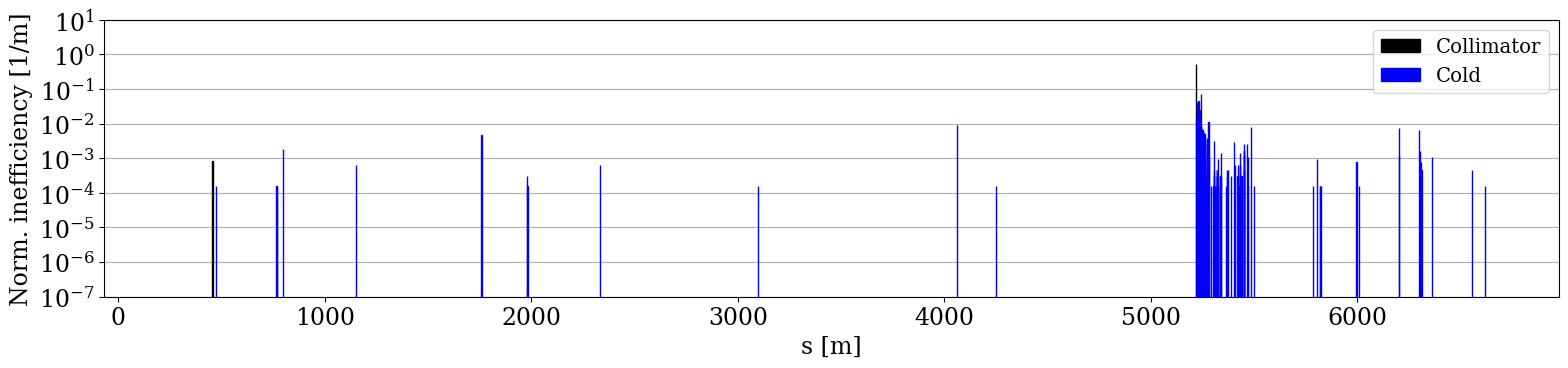

(<Figure size 1600x400 with 1 Axes>,
 <Axes: xlabel='s [m]', ylabel='Norm. inefficiency [1/m]'>)

In [ ]:
ThisLM = xc.LossMap(line = line, line_is_reversed=False, part=part, interpolation=False)
ThisLM.plot()

In [ ]:
# ThisLM.to_json('current_version_LM.json')

In [ ]:
# ThisLM.save_summary('new_version_summary.json')

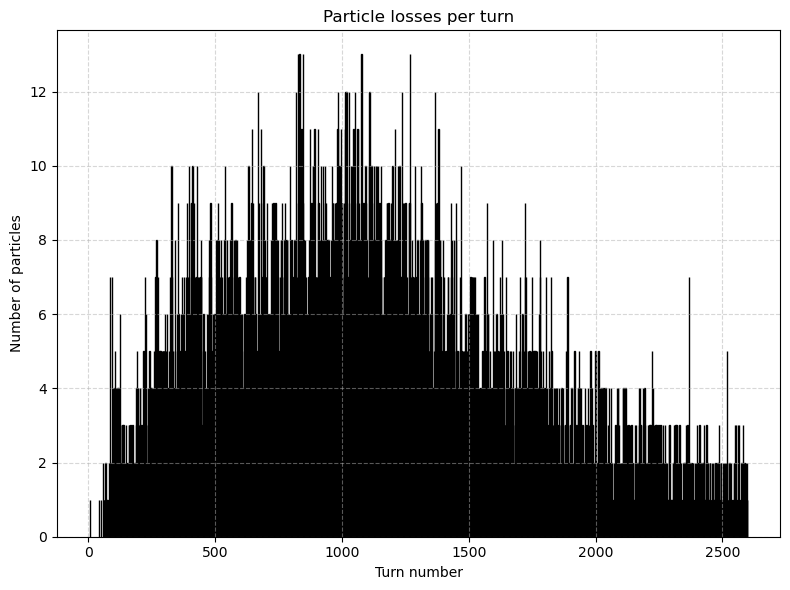

In [ ]:
plt.close('all')
mask = part.state > 0
unique_turns, counts = np.unique(part.at_turn[~mask], return_counts=True)

fig, ax = plt.subplots(figsize=(8, 6))
# Plot histogram-like bar chart
ax.bar(unique_turns, counts, width=1.0, edgecolor='black')
ax.set_xlabel("Turn number")
ax.set_ylabel("Number of particles")
ax.set_title("Particle losses per turn")
ax.grid(True, linestyle='--', alpha=0.5)
fig.tight_layout()
# plt.savefig(f'plots/adt_ramping/scheme1_10000part.png', dpi=300)
plt.show()